# Chinook Music Store: Sales Analysis with SQL

**Goal:** use SQL to answer business questions about an online music store: how revenue changes over time, which countries, genres and artists bring the most money, how concentrated the customer base is, and how the sales team performs.

**Data:** the Chinook sample database (SQLite): 59 customers, 412 invoices, 3,503 tracks, invoices from January 2021 to December 2025. Source: [lerocha/chinook-database](https://github.com/lerocha/chinook-database).

**Tools:** SQL (SQLite), Python, pandas, Matplotlib.

**SQL techniques used:** `JOIN` (up to 4 tables), `GROUP BY`, CTEs (`WITH`), window functions (`LAG`, `SUM() OVER`, `NTILE`), date functions.

> Note: Chinook is a sample database used for learning SQL, so the findings describe this dataset, not a real company.

## 1. Setup: load the database

In [1]:
import os
import sqlite3
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True

DB_URL = "https://raw.githubusercontent.com/lerocha/chinook-database/master/ChinookDatabase/DataSources/Chinook_Sqlite.sqlite"
DB_PATH = "chinook.sqlite"
if not os.path.exists(DB_PATH):
    urllib.request.urlretrieve(DB_URL, DB_PATH)

conn = sqlite3.connect(DB_PATH)

def run_sql(query):
    """Run an SQL query and return the result as a DataFrame."""
    return pd.read_sql_query(query, conn)

os.makedirs("images", exist_ok=True)

### Tables in the database

In [2]:
run_sql("""
SELECT name AS table_name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
""")

,table_name
0,Album
1,Artist
2,Customer
3,Employee
4,Genre
5,Invoice
6,InvoiceLine
7,MediaType
8,Playlist
9,PlaylistTrack


In [3]:
# Row counts for the tables used in this analysis
tables = ["Customer", "Invoice", "InvoiceLine", "Track", "Album", "Artist", "Genre", "Employee"]
pd.DataFrame({
    "table": tables,
    "rows": [run_sql(f"SELECT COUNT(*) AS n FROM {t}")["n"][0] for t in tables]
})

,table,rows
0,Customer,59
1,Invoice,412
2,InvoiceLine,2240
3,Track,3503
4,Album,347
5,Artist,275
6,Genre,25
7,Employee,8


**How the tables connect:** `Customer` → `Invoice` → `InvoiceLine` → `Track` → `Album` → `Artist`, and `Track` → `Genre`. Each customer is assigned to a sales rep from `Employee` via `SupportRepId`.

## 2. How does revenue change by year?

In [4]:
revenue_by_year = run_sql("""
SELECT strftime('%Y', InvoiceDate)       AS year,
       COUNT(*)                          AS invoices,
       COUNT(DISTINCT CustomerId)        AS active_customers,
       ROUND(SUM(Total), 2)              AS revenue,
       ROUND(AVG(Total), 2)              AS avg_invoice
FROM Invoice
GROUP BY year
ORDER BY year;
""")
revenue_by_year

,year,invoices,active_customers,revenue,avg_invoice
0,2021,83,46,449.46,5.42
1,2022,83,46,481.45,5.80
2,2023,83,47,469.58,5.66
3,2024,83,47,477.53,5.75
4,2025,80,46,450.58,5.63


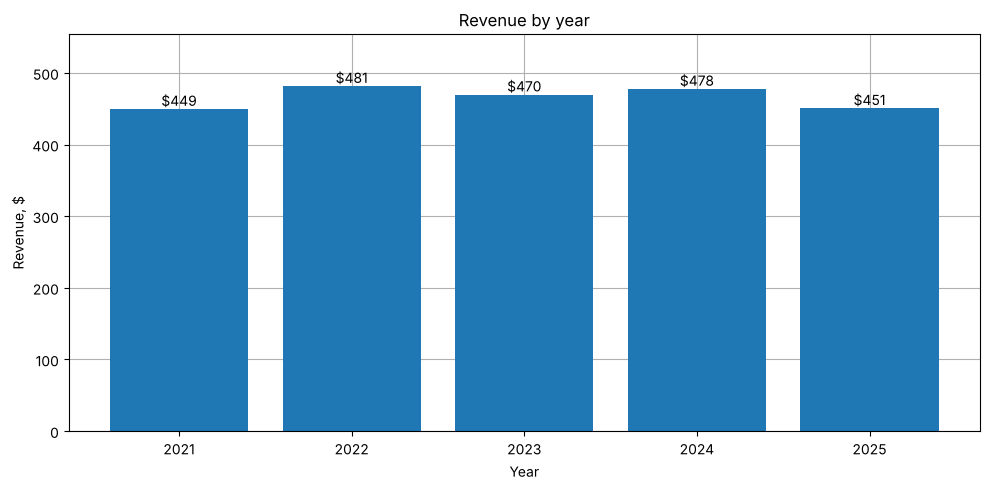

In [5]:
fig, ax = plt.subplots()
bars = ax.bar(revenue_by_year["year"], revenue_by_year["revenue"], color="tab:blue")
ax.bar_label(bars, fmt="$%.0f")
ax.set_title("Revenue by year")
ax.set_xlabel("Year")
ax.set_ylabel("Revenue, $")
ax.set_ylim(0, revenue_by_year["revenue"].max() * 1.15)
plt.tight_layout()
plt.savefig("images/revenue_by_year.png")
plt.show()

## 3. Monthly revenue, month-over-month growth and seasonality

A CTE aggregates revenue by month, then the window function `LAG` compares each month with the previous one.

In [6]:
monthly = run_sql("""
WITH monthly AS (
    SELECT strftime('%Y-%m', InvoiceDate) AS month,
           SUM(Total)                     AS revenue
    FROM Invoice
    GROUP BY month
)
SELECT month,
       ROUND(revenue, 2) AS revenue,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY month))
             / LAG(revenue) OVER (ORDER BY month), 1) AS mom_growth_pct
FROM monthly
ORDER BY month;
""")
monthly.head(14)

,month,revenue,mom_growth_pct
0,2021-01,35.64,NaN
1,2021-02,37.62,5.6
2,2021-03,37.62,0.0
3,2021-04,37.62,0.0
4,2021-05,37.62,0.0
5,2021-06,37.62,0.0
6,2021-07,37.62,0.0
7,2021-08,37.62,0.0
8,2021-09,37.62,0.0
9,2021-10,37.62,0.0


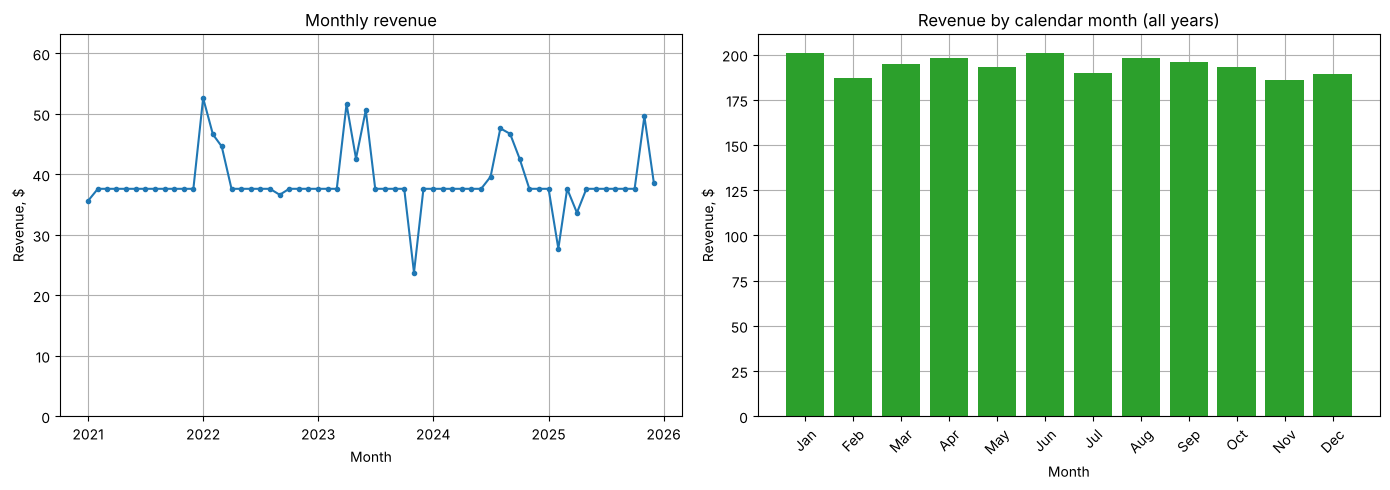

Lowest month: Nov 186.24
Highest month: Jan 201.12


In [7]:
seasonality = run_sql("""
SELECT strftime('%m', InvoiceDate) AS month_num,
       ROUND(SUM(Total), 2)        AS revenue
FROM Invoice
GROUP BY month_num
ORDER BY month_num;
""")
seasonality["month"] = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(pd.to_datetime(monthly["month"]), monthly["revenue"], marker="o", markersize=3)
axes[0].set_title("Monthly revenue")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue, $")
axes[0].set_ylim(0, monthly["revenue"].max() * 1.2)

axes[1].bar(seasonality["month"], seasonality["revenue"], color="tab:green")
axes[1].set_title("Revenue by calendar month (all years)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Revenue, $")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("images/monthly_revenue.png")
plt.show()

print("Lowest month:", seasonality.loc[seasonality.revenue.idxmin(), "month"], seasonality.revenue.min())
print("Highest month:", seasonality.loc[seasonality.revenue.idxmax(), "month"], seasonality.revenue.max())

## 4. Which countries bring the most revenue?

`SUM(SUM(Total)) OVER ()` is a window function over an aggregate: it gives the total revenue, so each country's share can be calculated in the same query.

In [8]:
countries = run_sql("""
SELECT BillingCountry                                     AS country,
       COUNT(DISTINCT CustomerId)                         AS customers,
       ROUND(SUM(Total), 2)                               AS revenue,
       ROUND(100.0 * SUM(Total) / SUM(SUM(Total)) OVER (), 1) AS revenue_share_pct,
       ROUND(SUM(Total) / COUNT(DISTINCT CustomerId), 2)  AS revenue_per_customer
FROM Invoice
GROUP BY country
ORDER BY revenue DESC
LIMIT 10;
""")
countries

,country,customers,revenue,revenue_share_pct,revenue_per_customer
0,USA,13,523.06,22.5,40.24
1,Canada,8,303.96,13.1,37.99
2,France,5,195.10,8.4,39.02
3,Brazil,5,190.10,8.2,38.02
4,Germany,4,156.48,6.7,39.12
5,United Kingdom,3,112.86,4.8,37.62
6,Czech Republic,2,90.24,3.9,45.12
7,Portugal,2,77.24,3.3,38.62
8,India,2,75.26,3.2,37.63
9,Chile,1,46.62,2.0,46.62


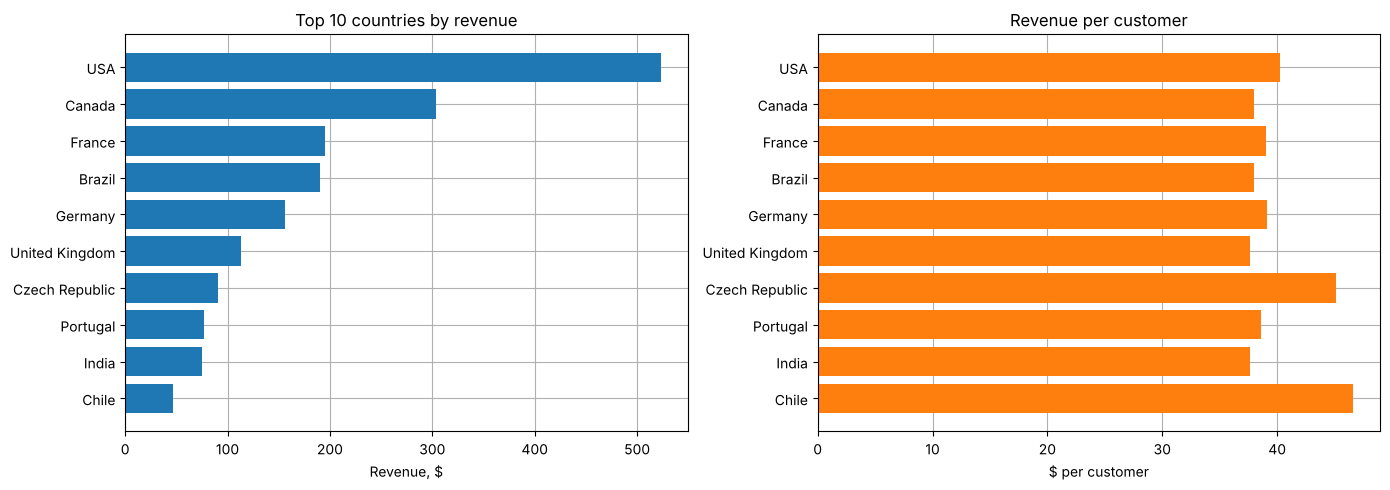

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top = countries.sort_values("revenue")
axes[0].barh(top["country"], top["revenue"], color="tab:blue")
axes[0].set_title("Top 10 countries by revenue")
axes[0].set_xlabel("Revenue, $")

axes[1].barh(top["country"], top["revenue_per_customer"], color="tab:orange")
axes[1].set_title("Revenue per customer")
axes[1].set_xlabel("$ per customer")

plt.tight_layout()
plt.savefig("images/countries.png")
plt.show()

## 5. Which genres and artists sell best?

This needs several joins: `InvoiceLine` → `Track` → `Genre` (and `Album` → `Artist` for artists).

In [10]:
genres = run_sql("""
SELECT g.Name                                              AS genre,
       SUM(il.Quantity)                                    AS units_sold,
       ROUND(SUM(il.UnitPrice * il.Quantity), 2)           AS revenue,
       ROUND(100.0 * SUM(il.UnitPrice * il.Quantity)
             / SUM(SUM(il.UnitPrice * il.Quantity)) OVER (), 1) AS revenue_share_pct,
       ROUND(SUM(il.UnitPrice * il.Quantity) / SUM(il.Quantity), 2) AS avg_price
FROM InvoiceLine il
JOIN Track t ON t.TrackId = il.TrackId
JOIN Genre g ON g.GenreId = t.GenreId
GROUP BY genre
ORDER BY revenue DESC
LIMIT 10;
""")
genres

,genre,units_sold,revenue,revenue_share_pct,avg_price
0,Rock,835,826.65,35.5,0.99
1,Latin,386,382.14,16.4,0.99
2,Metal,264,261.36,11.2,0.99
3,Alternative & Punk,244,241.56,10.4,0.99
4,TV Shows,47,93.53,4.0,1.99
5,Jazz,80,79.20,3.4,0.99
6,Blues,61,60.39,2.6,0.99
7,Drama,29,57.71,2.5,1.99
8,Classical,41,40.59,1.7,0.99
9,R&B/Soul,41,40.59,1.7,0.99


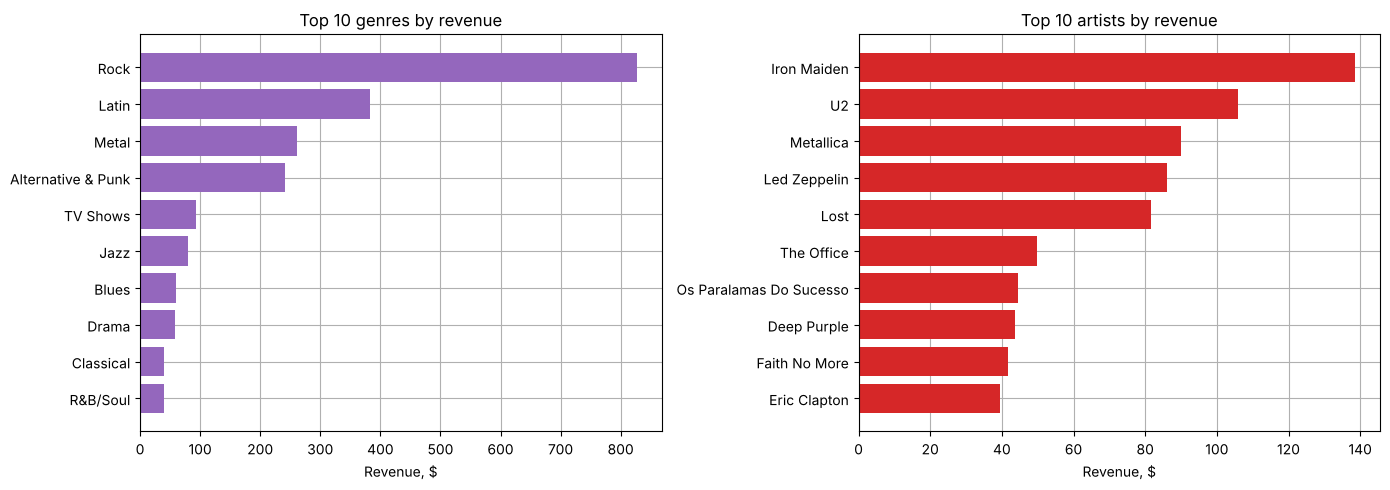

,artist,revenue,units_sold
0,Iron Maiden,138.60,140
1,U2,105.93,107
2,Metallica,90.09,91
3,Led Zeppelin,86.13,87
4,Lost,81.59,41
5,The Office,49.75,25
6,Os Paralamas Do Sucesso,44.55,45
7,Deep Purple,43.56,44
8,Faith No More,41.58,42
9,Eric Clapton,39.60,40


In [11]:
artists = run_sql("""
SELECT ar.Name                                    AS artist,
       ROUND(SUM(il.UnitPrice * il.Quantity), 2)  AS revenue,
       SUM(il.Quantity)                           AS units_sold
FROM InvoiceLine il
JOIN Track  t  ON t.TrackId  = il.TrackId
JOIN Album  al ON al.AlbumId = t.AlbumId
JOIN Artist ar ON ar.ArtistId = al.ArtistId
GROUP BY artist
ORDER BY revenue DESC
LIMIT 10;
""")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

g = genres.sort_values("revenue")
axes[0].barh(g["genre"], g["revenue"], color="tab:purple")
axes[0].set_title("Top 10 genres by revenue")
axes[0].set_xlabel("Revenue, $")

a = artists.sort_values("revenue")
axes[1].barh(a["artist"], a["revenue"], color="tab:red")
axes[1].set_title("Top 10 artists by revenue")
axes[1].set_xlabel("Revenue, $")

plt.tight_layout()
plt.savefig("images/genres_artists.png")
plt.show()

artists

## 6. How concentrated is the customer base?

`NTILE(10)` splits customers into 10 equal groups (deciles) by total spend. If a small group of customers brought most of the revenue, the top decile would have a big share.

In [12]:
deciles = run_sql("""
WITH customer_revenue AS (
    SELECT CustomerId, SUM(Total) AS revenue
    FROM Invoice
    GROUP BY CustomerId
),
ranked AS (
    SELECT CustomerId, revenue,
           NTILE(10) OVER (ORDER BY revenue DESC) AS decile
    FROM customer_revenue
)
SELECT decile,
       COUNT(*)                                            AS customers,
       ROUND(SUM(revenue), 2)                              AS revenue,
       ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS share_pct
FROM ranked
GROUP BY decile
ORDER BY decile;
""")
deciles

,decile,customers,revenue,share_pct
0,1,6,278.72,12.0
1,2,6,254.72,10.9
2,3,6,239.72,10.3
3,4,6,235.72,10.1
4,5,6,229.72,9.9
5,6,6,225.72,9.7
6,7,6,225.72,9.7
7,8,6,225.72,9.7
8,9,6,225.72,9.7
9,10,5,187.12,8.0


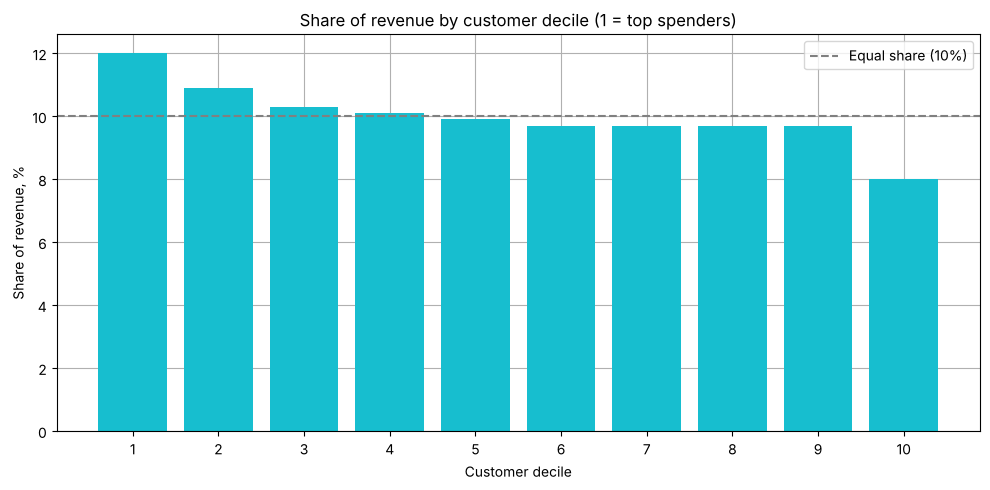

In [13]:
fig, ax = plt.subplots()
ax.bar(deciles["decile"].astype(str), deciles["share_pct"], color="tab:cyan")
ax.axhline(10, color="gray", linestyle="--", label="Equal share (10%)")
ax.set_title("Share of revenue by customer decile (1 = top spenders)")
ax.set_xlabel("Customer decile")
ax.set_ylabel("Share of revenue, %")
ax.legend()
plt.tight_layout()
plt.savefig("images/customer_deciles.png")
plt.show()

In [14]:
# Top 5 customers
run_sql("""
SELECT c.FirstName || ' ' || c.LastName AS customer,
       c.Country                         AS country,
       COUNT(i.InvoiceId)                AS invoices,
       ROUND(SUM(i.Total), 2)            AS total_spent
FROM Customer c
JOIN Invoice i ON i.CustomerId = c.CustomerId
GROUP BY c.CustomerId
ORDER BY total_spent DESC
LIMIT 5;
""")

,customer,country,invoices,total_spent
0,Helena Holý,Czech Republic,7,49.62
1,Richard Cunningham,USA,7,47.62
2,Luis Rojas,Chile,7,46.62
3,Ladislav Kovács,Hungary,7,45.62
4,Hugh O'Reilly,Ireland,7,45.62


## 7. Sales team performance

Each customer is assigned to a support rep. Joining `Employee` → `Customer` → `Invoice` shows revenue per rep and per assigned customer.

In [15]:
reps = run_sql("""
SELECT e.FirstName || ' ' || e.LastName   AS sales_rep,
       COUNT(DISTINCT c.CustomerId)       AS customers,
       ROUND(SUM(i.Total), 2)             AS revenue,
       ROUND(SUM(i.Total) / COUNT(DISTINCT c.CustomerId), 2) AS revenue_per_customer
FROM Employee e
JOIN Customer c ON c.SupportRepId = e.EmployeeId
JOIN Invoice  i ON i.CustomerId   = c.CustomerId
GROUP BY e.EmployeeId
ORDER BY revenue DESC;
""")
reps

,sales_rep,customers,revenue,revenue_per_customer
0,Jane Peacock,21,833.04,39.67
1,Margaret Park,20,775.40,38.77
2,Steve Johnson,18,720.16,40.01


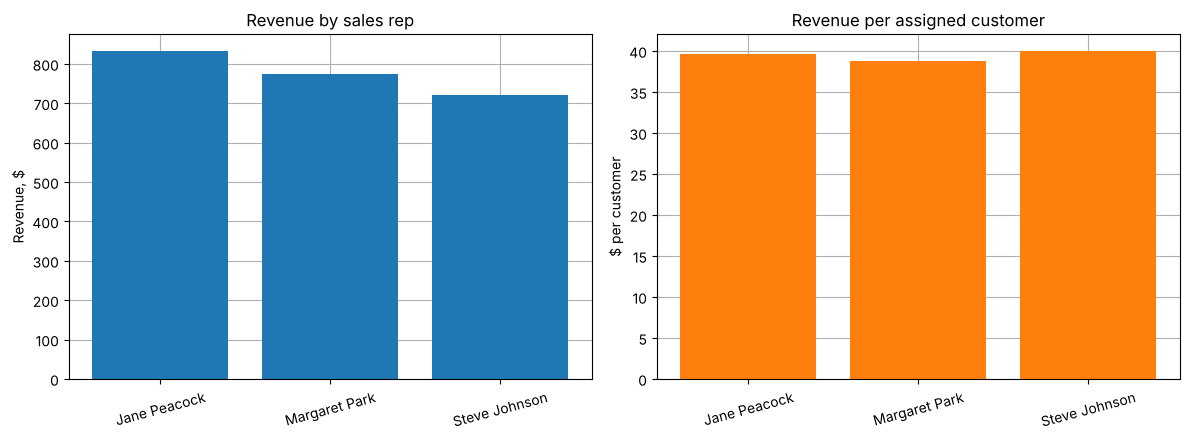

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(reps["sales_rep"], reps["revenue"], color="tab:blue")
axes[0].set_title("Revenue by sales rep")
axes[0].set_ylabel("Revenue, $")
axes[1].bar(reps["sales_rep"], reps["revenue_per_customer"], color="tab:orange")
axes[1].set_title("Revenue per assigned customer")
axes[1].set_ylabel("$ per customer")
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("images/sales_reps.png")
plt.show()

## 8. Findings

**Revenue over time**
- Revenue is stable: $449-481 per year with about 83 invoices a year. 2022 was the best year ($481.45, +7.1% vs 2021).
- 2025 is slightly lower ($450.58, 80 invoices), but the data ends on 22 December 2025, so part of the difference may be an incomplete last month.
- There is no strong seasonality: the weakest calendar month (November, $186) and the strongest (January, $201) differ by only about 8%.

**Markets**
- The USA brings 22.5% of revenue and Canada 13.1%. The top 5 countries (USA, Canada, France, Brazil, Germany) account for about 59%.
- Revenue per customer is similar everywhere (about $38-40). Countries differ mainly in the *number* of customers, not in how much each customer spends. Czech Republic and Chile look higher per customer, but they have only 1-2 customers, so this is not reliable.

**Products**
- Rock alone is 35.5% of revenue. The top 4 genres (Rock, Latin, Metal, Alternative & Punk) give about 73.5%.
- Iron Maiden, U2, Metallica and Led Zeppelin are the top music artists.
- TV content (TV Shows, Drama) sells at $1.99 per unit versus $0.99 for music, so a small number of units gives a noticeable share (6.5% of revenue from 76 units).

**Customers and team**
- The customer base is not concentrated: the top 10% of customers bring 12.0% of revenue, the bottom 10% bring 8.0%. The biggest customer spent $49.62 (2.1% of revenue). The business does not depend on a few key customers.
- Sales reps differ in revenue ($720-833) mostly because of portfolio size (18-21 customers). Revenue per assigned customer is almost the same ($38.8-40.0).

**Ideas to test (based on the data)**
1. Since customers spend about the same, growth will mostly come from acquiring *more* customers, especially in the core North American market, and from increasing purchase frequency or basket size.
2. Test promotions of higher-priced TV content, which earns about twice as much per unit.
3. Rock, Latin, Metal and Alternative & Punk are the core catalogue, so keep them in focus when choosing what to promote or license.

**Limitations**
- Chinook is a sample database, so these findings describe this dataset, not a real business.
- There are only 59 customers, so country-level comparisons for small markets are statistically weak.
- Revenue here is based on invoice totals; there is no data on costs, so profit cannot be estimated.